In [4]:
%pip install -q ucimlrepo



ERROR: Operation cancelled by user
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/base_command.py", line 179, in exc_logging_wrapper
    status = run_func(*args)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/cli/req_command.py", line 67, in wrapper
    return func(self, options, args)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/commands/install.py", line 447, in run
    conflicts = self._determine_conflicts(to_install)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/commands/install.py", line 578, in _determine_conflicts
    return check_install_conflicts(to_install)
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/operations/check.py", line 101, in check_install_conflicts
    package_set, _ = create_package_set_from_installed()
                     ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/pip/_internal/operations/check.py", line 

KeyboardInterrupt: 

# Imports


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo


# Chargement des données


In [6]:
wine_quality = fetch_ucirepo(id=186)

X = wine_quality.data.features
y = wine_quality.data.targets

df = pd.concat([X, y], axis=1)
df.head()


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


# Métadonnées et variables


In [7]:
print(wine_quality.metadata)
print(wine_quality.variables)


{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeling wine preferences

# Structure du jeu de données


In [8]:
print(df.shape)
df.info()


(6497, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         6497 non-null   float64
 1   volatile_acidity      6497 non-null   float64
 2   citric_acid           6497 non-null   float64
 3   residual_sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free_sulfur_dioxide   6497 non-null   float64
 6   total_sulfur_dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 609.2 KB


# Statistiques descriptives


In [9]:
df.describe().round(2)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00,6497.00
mean,7.22,0.34,0.32,5.44,0.06,30.53,115.74,0.99,3.22,0.53,10.49,5.82
std,1.30,0.16,0.15,4.76,0.04,17.75,56.52,0.00,0.16,0.15,1.19,0.87
min,3.80,0.08,0.00,0.60,0.01,1.00,6.00,0.99,2.72,0.22,8.00,3.00
25%,6.40,0.23,0.25,1.80,0.04,17.00,77.00,0.99,3.11,0.43,9.50,5.00
50%,7.00,0.29,0.31,3.00,0.05,29.00,118.00,0.99,3.21,0.51,10.30,6.00
75%,7.70,0.40,0.39,8.10,0.06,41.00,156.00,1.00,3.32,0.60,11.30,6.00
max,15.90,1.58,1.66,65.80,0.61,289.00,440.00,1.04,4.01,2.00,14.90,9.00


On peut observer que certaines molécules sont de l'ordre de 100+ en moyenne et d'autres 0.06, il faudra donc normaliser si on ne veut pas que les grosses valeurs écrasent les autres.

On constate aussi qu'il y a des valeurs extrêmes qui tirent la moyenne vers le haut comme le sucre. Il faudra surveiller ce bruit.


# Vérification des valeurs manquantes


In [10]:
df.isna().sum()


,0
fixed_acidity,0
volatile_acidity,0
citric_acid,0
residual_sugar,0
chlorides,0
free_sulfur_dioxide,0
total_sulfur_dioxide,0
density,0
pH,0
sulphates,0


# Détection des valeurs aberrantes par l'écart interquartile


In [11]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.drop("quality")
q1 = df[numeric_cols].quantile(0.25)
q3 = df[numeric_cols].quantile(0.75)
iqr = q3 - q1
outliers = ((df[numeric_cols] < (q1 - 1.5 * iqr)) | (df[numeric_cols] > (q3 + 1.5 * iqr))).sum()
outliers


,0
fixed_acidity,357
volatile_acidity,377
citric_acid,509
residual_sugar,118
chlorides,286
free_sulfur_dioxide,62
total_sulfur_dioxide,10
density,3
pH,73
sulphates,191


# Proportion des valeurs aberrantes


In [12]:
(outliers / len(df) * 100).round(2)


,0
fixed_acidity,5.49
volatile_acidity,5.80
citric_acid,7.83
residual_sugar,1.82
chlorides,4.40
free_sulfur_dioxide,0.95
total_sulfur_dioxide,0.15
density,0.05
pH,1.12
sulphates,2.94


On constate qu'il y a une grosse part de valeurs aberrantes dans certaines colonnes, mais étant donné qu'on sait que ce ne sont pas des erreurs, on ne les supprime pas pour ne pas biaiser le modèle.


# Encodage de la variable catégorielle


In [13]:
if "color" in wine_quality.data.original.columns:
    df["color"] = wine_quality.data.original["color"].map({"red": 1, "white": 0})
df["color"].value_counts()


,count
color,
0,4898
1,1599


# Création de la cible binaire


In [14]:
df["good_wine"] = (df["quality"] >= 7).astype(int)
df[["quality", "good_wine"]].head()


,quality,good_wine
0,5,0
1,5,0
2,5,0
3,6,0
4,5,0


# Répartition des notes de qualité d'origine


In [15]:
df["quality"].value_counts().sort_index()


,count
quality,
3,30
4,216
5,2138
6,2836
7,1079
8,193
9,5


# Distribution de la cible binaire


In [16]:
counts = df["good_wine"].value_counts()
proportions = (df["good_wine"].value_counts(normalize=True) * 100).round(2)
pd.DataFrame({"effectif": counts, "pourcentage": proportions})


,effectif,pourcentage
good_wine,,
0,5220,80.34
1,1277,19.66


Ici on remarque un déséquilibre conséquent entre les 2 classes. Ainsi on sait qu'il faut faire attention à l'accuracy car un modèle qui prédit 100% de vin ordinaire aurait une accuracy à 80%.


# Visualisation du déséquilibre des classes


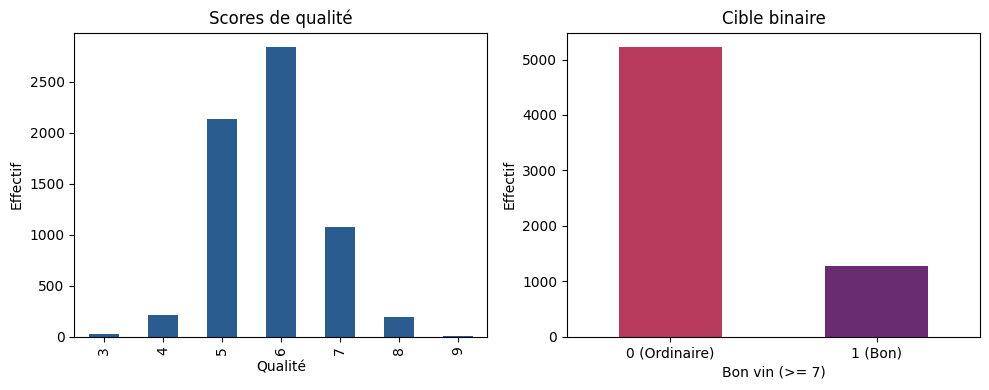

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df["quality"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="#2b5c8f")
axes[0].set_title("Scores de qualité")
axes[0].set_xlabel("Qualité")
axes[0].set_ylabel("Effectif")

df["good_wine"].value_counts().plot(kind="bar", ax=axes[1], color=["#b83b5e", "#6a2c70"])
axes[1].set_title("Cible binaire")
axes[1].set_xlabel("Bon vin (>= 7)")
axes[1].set_ylabel("Effectif")
axes[1].set_xticklabels(["0 (Ordinaire)", "1 (Bon)"], rotation=0)

plt.tight_layout()
plt.show()


On distingue bien l'écart sur ces 2 graphiques.


# Matrice de corrélation


In [18]:
corr_matrix = df.corr().round(2)
corr_matrix


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color,good_wine
fixed_acidity,1.00,0.22,0.32,-0.11,0.30,-0.28,-0.33,0.46,-0.25,0.30,-0.10,-0.08,0.49,-0.05
volatile_acidity,0.22,1.00,-0.38,-0.20,0.38,-0.35,-0.41,0.27,0.26,0.23,-0.04,-0.27,0.65,-0.15
citric_acid,0.32,-0.38,1.00,0.14,0.04,0.13,0.20,0.10,-0.33,0.06,-0.01,0.09,-0.19,0.05
residual_sugar,-0.11,-0.20,0.14,1.00,-0.13,0.40,0.50,0.55,-0.27,-0.19,-0.36,-0.04,-0.35,-0.06
chlorides,0.30,0.38,0.04,-0.13,1.00,-0.20,-0.28,0.36,0.04,0.40,-0.26,-0.20,0.51,-0.16
free_sulfur_dioxide,-0.28,-0.35,0.13,0.40,-0.20,1.00,0.72,0.03,-0.15,-0.19,-0.18,0.06,-0.47,0.01
total_sulfur_dioxide,-0.33,-0.41,0.20,0.50,-0.28,0.72,1.00,0.03,-0.24,-0.28,-0.27,-0.04,-0.70,-0.05
density,0.46,0.27,0.10,0.55,0.36,0.03,0.03,1.00,0.01,0.26,-0.69,-0.31,0.39,-0.28
pH,-0.25,0.26,-0.33,-0.27,0.04,-0.15,-0.24,0.01,1.00,0.19,0.12,0.02,0.33,0.03
sulphates,0.30,0.23,0.06,-0.19,0.40,-0.19,-0.28,0.26,0.19,1.00,-0.00,0.04,0.49,0.03


# Corrélations avec la cible binaire


In [19]:
target_corr = corr_matrix["good_wine"].sort_values(ascending=False)
target_corr


,good_wine
good_wine,1.00
quality,0.76
alcohol,0.39
citric_acid,0.05
sulphates,0.03
pH,0.03
free_sulfur_dioxide,0.01
total_sulfur_dioxide,-0.05
fixed_acidity,-0.05
residual_sugar,-0.06


# Visualisation de la matrice de corrélation


On voit nettement que ce qui joue un rôle dans un bon vin c'est forcément la qualité, mais aussi le niveau d'alcool. A contrario, plus le vin a de densité, volatilité, chlorure, moins il a de chances d'être un bon vin.


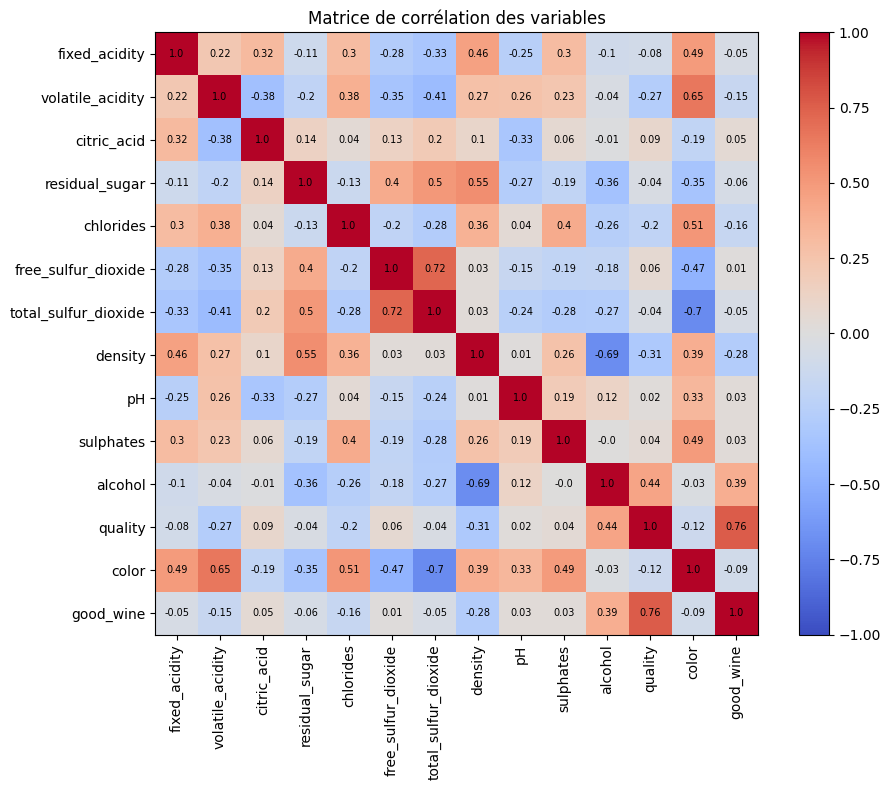

In [20]:
plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        plt.text(j, i, corr_matrix.iloc[i, j], ha="center", va="center", color="black", fontsize=7)
plt.title("Matrice de corrélation des variables")
plt.tight_layout()
plt.show()


Ici on peut voir les corrélations entre chaque variable. D'abord ce qui nous intéresse, la qualité, et on retrouve notre alcool qui influence positivement, et la densité, volatilité et chlorure qui influencent négativement.
Quand on se penche sur d'autres combinaisons, on constate de manière logique que l'alcool et la densité sont très corrélés négativement.


# Distributions des variables physico-chimiques


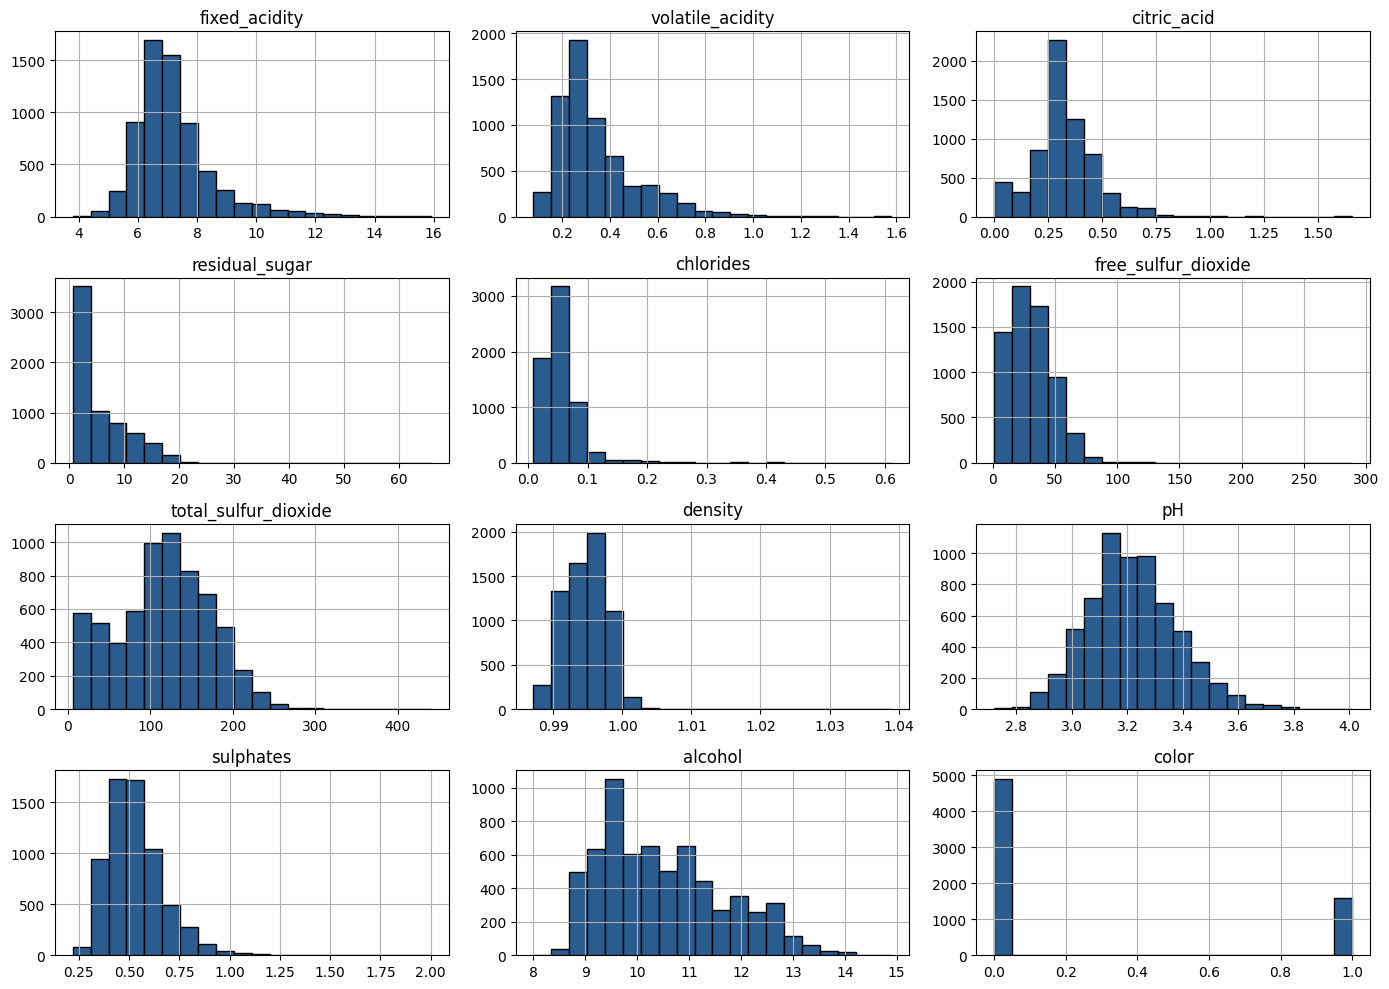

In [21]:
features = [col for col in df.columns if col not in ["quality", "good_wine"]]
df[features].hist(bins=20, figsize=(14, 10), color="#2b5c8f", edgecolor="black", layout=(4, 3))
plt.tight_layout()
plt.show()


# Boxplots des variables selon la qualité du vin


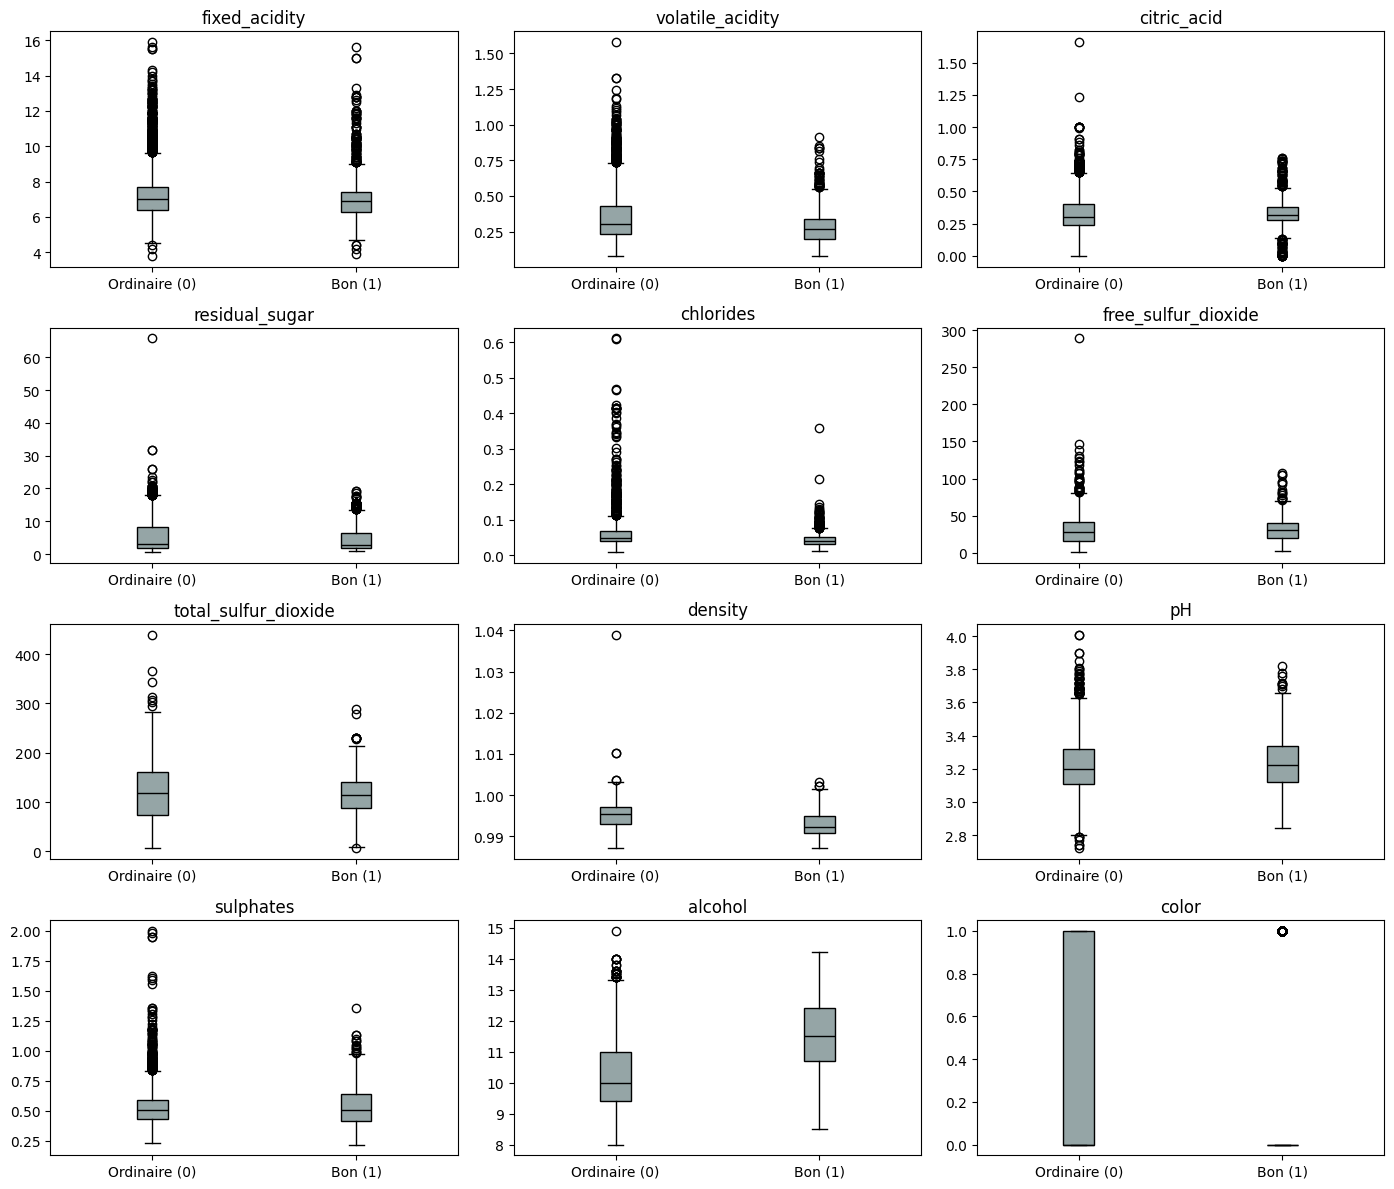

In [22]:
fig, axes = plt.subplots(4, 3, figsize=(14, 12))
axes = axes.flatten()

for i, col in enumerate(features):
    data_to_plot = [df[df["good_wine"] == 0][col].dropna(), df[df["good_wine"] == 1][col].dropna()]
    axes[i].boxplot(data_to_plot, patch_artist=True, boxprops=dict(facecolor="#95a5a6"), medianprops=dict(color="black"))
    axes[i].set_title(col)
    axes[i].set_xticklabels(["Ordinaire (0)", "Bon (1)"])

for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


Ici on confirme nos analyses sur la matrice de corrélation car le taux moyen d'alcool est plus élevé chez les bons vins que chez les ordinaires. Et inversement pour nos 3 autres variables qui corrèlent négativement avec la qualité.


# Définition des variables explicatives et de la cible


In [23]:
X_data = df.drop(columns=["quality", "good_wine"])
y_data = df["good_wine"]


# Séparation des données en ensembles d'entraînement et de test


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=42, stratify=y_data
)
print(X_train.shape, X_test.shape)


(5197, 12) (1300, 12)


# Standardisation des variables numériques


In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# Sélection univariée avec SelectKBest et le test ANOVA


In [26]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(score_func=f_classif, k="all")
selector.fit(X_train_scaled, y_train)

scores_df = pd.DataFrame({
    "variable": X_data.columns,
    "score_f": selector.scores_.round(2),
    "p_value": selector.pvalues_
}).sort_values(by="score_f", ascending=False)
scores_df


,variable,score_f,p_value
10,alcohol,927.60,1.319596e-187
7,density,410.99,5.239167e-88
4,chlorides,135.68,5.662737e-31
1,volatile_acidity,127.55,3.083682e-29
11,color,45.19,1.980334e-11
3,residual_sugar,15.69,7.548640e-05
2,citric_acid,15.52,8.278512e-05
0,fixed_acidity,13.21,2.816148e-04
6,total_sulfur_dioxide,10.49,1.210989e-03
9,sulphates,4.71,3.008969e-02


# Classement graphique des variables selon le score F


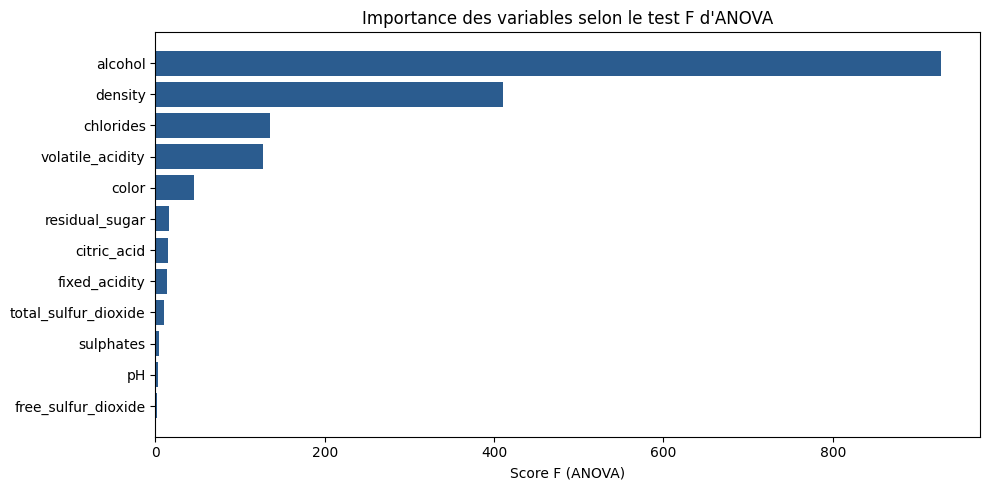

In [27]:
plt.figure(figsize=(10, 5))
plt.barh(scores_df["variable"][::-1], scores_df["score_f"][::-1], color="#2b5c8f")
plt.xlabel("Score F (ANOVA)")
plt.title("Importance des variables selon le test F d'ANOVA")
plt.tight_layout()
plt.show()


Le classement confirme encore ce que nous disions avant. Nos 4 variables ont les scores F les plus élevés et de loin, particulièrement pour l'alcool.


# Régression Logistique : entraînement et prédiction


In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

lr_model = LogisticRegression(solver="liblinear", random_state=42)
lr_model.fit(X_train_scaled, y_train)

y_pred_lr = lr_model.predict(X_test_scaled)
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]


# Métriques de performance de la Régression Logistique


In [29]:
lr_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_lr),
    "Précision": precision_score(y_test, y_pred_lr),
    "Rappel": recall_score(y_test, y_pred_lr),
    "F1-score": f1_score(y_test, y_pred_lr),
    "ROC-AUC": roc_auc_score(y_test, y_prob_lr)
}
pd.Series(lr_metrics).round(4)


,0
Accuracy,0.8231
Précision,0.6182
Rappel,0.2656
F1-score,0.3716
ROC-AUC,0.8048


# Matrice de confusion de la Régression Logistique


In [30]:
print(confusion_matrix(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr, target_names=["Ordinaire (0)", "Bon (1)"]))


[[1002   42]
 [ 188   68]]
               precision    recall  f1-score   support

Ordinaire (0)       0.84      0.96      0.90      1044
      Bon (1)       0.62      0.27      0.37       256

     accuracy                           0.82      1300
    macro avg       0.73      0.61      0.63      1300
 weighted avg       0.80      0.82      0.79      1300



# k-NN : entraînement et prédiction


In [31]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

y_pred_knn = knn_model.predict(X_test_scaled)
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]


# Métriques de performance de k-NN


In [32]:
knn_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_knn),
    "Précision": precision_score(y_test, y_pred_knn),
    "Rappel": recall_score(y_test, y_pred_knn),
    "F1-score": f1_score(y_test, y_pred_knn),
    "ROC-AUC": roc_auc_score(y_test, y_prob_knn)
}
pd.Series(knn_metrics).round(4)


,0
Accuracy,0.8323
Précision,0.5922
Rappel,0.4766
F1-score,0.5281
ROC-AUC,0.8264


# Matrice de confusion de k-NN


In [33]:
print(confusion_matrix(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn, target_names=["Ordinaire (0)", "Bon (1)"]))


[[960  84]
 [134 122]]
               precision    recall  f1-score   support

Ordinaire (0)       0.88      0.92      0.90      1044
      Bon (1)       0.59      0.48      0.53       256

     accuracy                           0.83      1300
    macro avg       0.73      0.70      0.71      1300
 weighted avg       0.82      0.83      0.83      1300



# Arbre de Décision : entraînement et prédiction


In [34]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42, max_depth=5)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]


# Métriques de performance de l'Arbre de Décision


In [35]:
dt_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_dt),
    "Précision": precision_score(y_test, y_pred_dt),
    "Rappel": recall_score(y_test, y_pred_dt),
    "F1-score": f1_score(y_test, y_pred_dt),
    "ROC-AUC": roc_auc_score(y_test, y_prob_dt)
}
pd.Series(dt_metrics).round(4)


,0
Accuracy,0.8315
Précision,0.6480
Rappel,0.3164
F1-score,0.4252
ROC-AUC,0.8269


# Matrice de confusion de l'Arbre de Décision


In [36]:
print(confusion_matrix(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt, target_names=["Ordinaire (0)", "Bon (1)"]))


[[1000   44]
 [ 175   81]]
               precision    recall  f1-score   support

Ordinaire (0)       0.85      0.96      0.90      1044
      Bon (1)       0.65      0.32      0.43       256

     accuracy                           0.83      1300
    macro avg       0.75      0.64      0.66      1300
 weighted avg       0.81      0.83      0.81      1300



# Importance des variables selon l'Arbre de Décision


In [37]:
dt_importance = pd.Series(dt_model.feature_importances_, index=X_data.columns).sort_values(ascending=False)
dt_importance.round(4)


,0
alcohol,0.5218
citric_acid,0.1012
volatile_acidity,0.0819
sulphates,0.0697
chlorides,0.0599
free_sulfur_dioxide,0.0415
density,0.0374
residual_sugar,0.0333
pH,0.0299
fixed_acidity,0.0142


# Naive Bayes : entraînement et prédiction


In [38]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

y_pred_nb = nb_model.predict(X_test_scaled)
y_prob_nb = nb_model.predict_proba(X_test_scaled)[:, 1]


# Métriques de performance de Naive Bayes


In [39]:
nb_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_nb),
    "Précision": precision_score(y_test, y_pred_nb),
    "Rappel": recall_score(y_test, y_pred_nb),
    "F1-score": f1_score(y_test, y_pred_nb),
    "ROC-AUC": roc_auc_score(y_test, y_prob_nb)
}
pd.Series(nb_metrics).round(4)


,0
Accuracy,0.7346
Précision,0.3901
Rappel,0.6172
F1-score,0.4781
ROC-AUC,0.7486


# Matrice de confusion de Naive Bayes


In [40]:
print(confusion_matrix(y_test, y_pred_nb))
print(classification_report(y_test, y_pred_nb, target_names=["Ordinaire (0)", "Bon (1)"]))


[[797 247]
 [ 98 158]]
               precision    recall  f1-score   support

Ordinaire (0)       0.89      0.76      0.82      1044
      Bon (1)       0.39      0.62      0.48       256

     accuracy                           0.73      1300
    macro avg       0.64      0.69      0.65      1300
 weighted avg       0.79      0.73      0.75      1300



# SVM : entraînement et prédiction


In [41]:
from sklearn.svm import SVC

svm_model = SVC(kernel="rbf", probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]


# Métriques de performance de SVM


In [42]:
svm_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_svm),
    "Précision": precision_score(y_test, y_pred_svm),
    "Rappel": recall_score(y_test, y_pred_svm),
    "F1-score": f1_score(y_test, y_pred_svm),
    "ROC-AUC": roc_auc_score(y_test, y_prob_svm)
}
pd.Series(svm_metrics).round(4)


,0
Accuracy,0.8285
Précision,0.6634
Rappel,0.2617
F1-score,0.3754
ROC-AUC,0.8414


# Matrice de confusion de SVM


In [43]:
print(confusion_matrix(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm, target_names=["Ordinaire (0)", "Bon (1)"]))


[[1010   34]
 [ 189   67]]
               precision    recall  f1-score   support

Ordinaire (0)       0.84      0.97      0.90      1044
      Bon (1)       0.66      0.26      0.38       256

     accuracy                           0.83      1300
    macro avg       0.75      0.61      0.64      1300
 weighted avg       0.81      0.83      0.80      1300



# Tableau comparatif des performances des modèles


In [44]:
comparison_df = pd.DataFrame({
    "Régression Logistique": lr_metrics,
    "k-NN": knn_metrics,
    "Arbre de Décision": dt_metrics,
    "Naive Bayes": nb_metrics,
    "SVM": svm_metrics
}).T
comparison_df.round(4)


,Accuracy,Précision,Rappel,F1-score,ROC-AUC
Régression Logistique,0.8231,0.6182,0.2656,0.3716,0.8048
k-NN,0.8323,0.5922,0.4766,0.5281,0.8264
Arbre de Décision,0.8315,0.6480,0.3164,0.4252,0.8269
Naive Bayes,0.7346,0.3901,0.6172,0.4781,0.7486
SVM,0.8285,0.6634,0.2617,0.3754,0.8414


# Courbes ROC comparatives


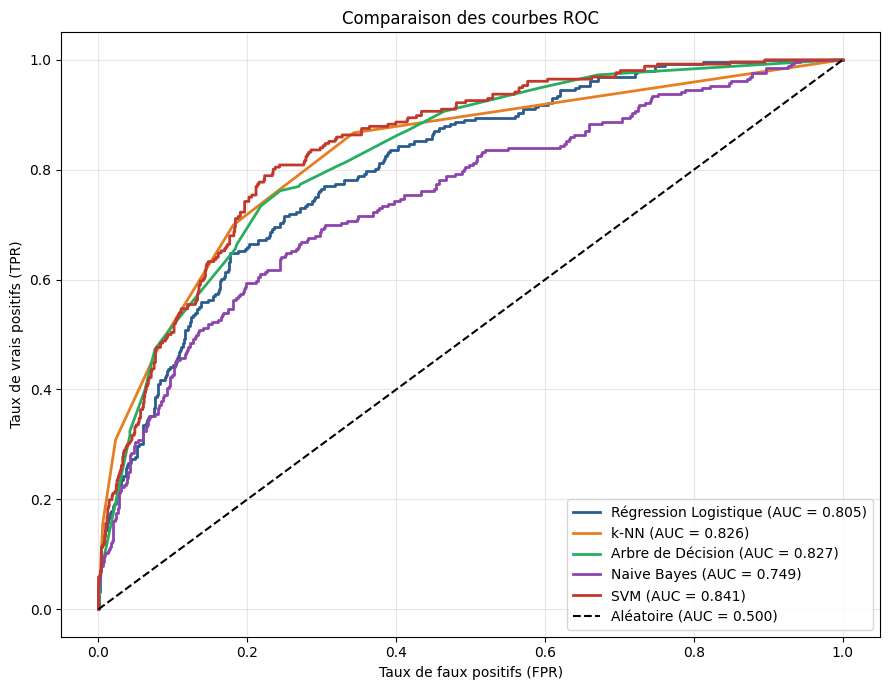

In [45]:
from sklearn.metrics import roc_curve

models_probs = {
    "Régression Logistique": (y_prob_lr, "#2b5c8f"),
    "k-NN": (y_prob_knn, "#e67e22"),
    "Arbre de Décision": (y_prob_dt, "#27ae60"),
    "Naive Bayes": (y_prob_nb, "#8e44ad"),
    "SVM": (y_prob_svm, "#c0392b")
}

plt.figure(figsize=(9, 7))
for name, (probs, col) in models_probs.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", color=col, linewidth=2)

plt.plot([0, 1], [0, 1], "k--", label="Aléatoire (AUC = 0.500)")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Comparaison des courbes ROC")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Régression Logistique : Rapide mais trop rigide. Avec une frontière de décision linéaire, elle rate la plupart des bons vins.

Naive Bayes : Présente le rappel le plus fort de base (61.7%), mais il a une précision catastrophique (39%). Cela s'explique par l'hypothèse d'indépendance conditionnelle entre les variables alcool, densité et sucre. Or nous avons vu que ce n'était pas le cas.

Arbre de Décision : Performance modérée (F1 ~0.43). Une assez bonne précision et accuracy, mais le rappel pèche.

SVM : Excellente précision (66.3%) et le meilleur score AUC (0.832), mais le pire rappel, on se rapproche du schéma contre lequel on s'était mis en garde au début : un modèle qui prédit majoritairement des vins ordinaires. C'est pour ça que je le classerais 2ème modèle initial.

k-NN : Meilleur modèle initial global avec une bonne polyvalence, en effet un F1-score de 0.530. Tout en ayant la meilleure accuracy (0.8323) et un bon ROC-AUC.


# Optimisation par Grid Search sur k-NN


In [46]:
from sklearn.model_selection import GridSearchCV

param_grid_knn = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan"]
}

grid_knn = GridSearchCV(
    KNeighborsClassifier(),
    param_grid_knn,
    cv=5,
    scoring="f1",
    n_jobs=-1
)
grid_knn.fit(X_train_scaled, y_train)

best_knn = grid_knn.best_estimator_
y_pred_best_knn = best_knn.predict(X_test_scaled)

print(grid_knn.best_params_)
print(f1_score(y_test, y_pred_best_knn))


{'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'distance'}
0.649895178197065


# Optimisation par Random Search sur SVM


In [47]:
from sklearn.model_selection import RandomizedSearchCV

param_dist_svc = {
    "C": [0.1, 1, 5, 10, 20],
    "gamma": ["scale", "auto", 0.01, 0.05, 0.1]
}

rand_svc = RandomizedSearchCV(
    SVC(kernel="rbf", random_state=42),
    param_dist_svc,
    n_iter=10,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1
)
rand_svc.fit(X_train_scaled, y_train)

best_svc = rand_svc.best_estimator_
y_pred_best_svc = best_svc.predict(X_test_scaled)

print(rand_svc.best_params_)
print(f1_score(y_test, y_pred_best_svc))


{'gamma': 'auto', 'C': 10}
0.5096153846153846


# Comparaison des modèles optimisés sur l'échantillon test


In [48]:
optimized_comparison = pd.DataFrame({
    "k-NN Optimisé": {
        "Accuracy": accuracy_score(y_test, y_pred_best_knn),
        "Précision": precision_score(y_test, y_pred_best_knn),
        "Rappel": recall_score(y_test, y_pred_best_knn),
        "F1-score": f1_score(y_test, y_pred_best_knn)
    },
    "SVM Optimisé": {
        "Accuracy": accuracy_score(y_test, y_pred_best_svc),
        "Précision": precision_score(y_test, y_pred_best_svc),
        "Rappel": recall_score(y_test, y_pred_best_svc),
        "F1-score": f1_score(y_test, y_pred_best_svc)
    }
}).T
optimized_comparison.round(4)


,Accuracy,Précision,Rappel,F1-score
k-NN Optimisé,0.8715,0.7014,0.6055,0.6499
SVM Optimisé,0.8431,0.6625,0.4141,0.5096


Après optimisation il n'y a plus photo, le k-NN surclasse complètement le SVM. Et cela sur chaque métrique. Nous allons donc choisir ce modèle pour la suite.


# Évaluation finale du modèle retenu (k-NN optimisé)


In [ ]:
final_model = best_knn
y_pred_final = final_model.predict(X_test_scaled)

print(confusion_matrix(y_test, y_pred_final))
print(classification_report(y_test, y_pred_final, target_names=["Ordinaire (0)", "Bon (1)"]))


Au final 
978 vins ordinaires correctement identifiés comme ordinaires.                                                                    
155 vrais bons vins correctement repérés.
Seulement 66 vins ordinaires pris par erreur pour des bons vins (le modèle est fiable à 70% de Précision).
101 bons vins classés comme ordinaires mais ça reste le meilleur rappel atteint (60.5%).

On a assurément évité le sous apprentissage de model comme la régression logistique Mais aussi le sur apprentisage en choissant le meilleur k : k = 5 pour notre model k-nn, grâce à l'optimisation avec grid shearch

# Sauvegarde du modèle et du scaler


In [ ]:
import joblib

joblib.dump(final_model, "best_knn_model.joblib")
joblib.dump(scaler, "scaler.joblib")


# Test de rechargement et prédiction sur un échantillon


In [ ]:
loaded_model = joblib.load("best_knn_model.joblib")
loaded_scaler = joblib.load("scaler.joblib")

sample_wine = X_test.iloc[0:1]
sample_scaled = loaded_scaler.transform(sample_wine)
prediction = loaded_model.predict(sample_scaled)
probability = loaded_model.predict_proba(sample_scaled)[0, 1]

print(prediction[0], round(probability, 4))
